## Churn Analysis and Customer Intelligence

## 1.Import database / data

In [1]:
# Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
# Excel file path
excel_file = 'customer_churn_data.xlsx'

# Create SQLite database connection
conn = sqlite3.connect('customer_churn.db')

# Read all sheet names from Excel file
excel_data = pd.ExcelFile(excel_file)

# Loop through each sheet store as separate table
for sheet in excel_data.sheet_names:
    df = pd.read_excel(excel_file, sheet_name = sheet) # Read sheet into dataframe 
    
    # Write dataframe to SQLite table
    df.to_sql(
        name = sheet,          # Table name = Sheet name
        con = conn,
        if_exists = 'replace', # Replace table if already exists
        index = False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [3]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database
conn = sqlite3.connect('customer_churn.db')

# Sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table';
"""

# Read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# Create DataFrame for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [4]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [5]:
# PRAGMA is a special command in SQLite used to inspect db information, control db settings, retrieve metadata about tables.

## 2. Data Cleaning

### i. Customer Table

In [6]:
df_db_customer.head()      # customer table
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
1016,NEW010995,Ira Pillai,India,Punjab,Male,1984-02-16 00:00:00,sports,290566.0
1017,NEW010996,Kabir Malhotra,India,Gujarat,Female,1963-09-14 00:00:00,travel,772036.0
1018,NEW010997,Ishaan Kapoor,India,Telangana,Female,1966-07-23 00:00:00,gaming,837504.0
1019,NEW010998,Ishaan Nair,India,Bihar,Male,1971-12-20 00:00:00,fitness,710674.0
1020,NEW010999,Karan Shah,India,Gujarat,Male,1986-01-28 00:00:00,technology,548739.0


In [7]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1021 entries, 0 to 1020
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  1021 non-null   object 
 1   name        1021 non-null   object 
 2   country     1018 non-null   object 
 3   state       1021 non-null   object 
 4   gender      1021 non-null   object 
 5   dob         1021 non-null   object 
 6   interests   909 non-null    object 
 7   pincode     1000 non-null   float64
dtypes: float64(1), object(7)
memory usage: 63.9+ KB


In [8]:
# Here, I understand some paterns from the data.

# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country

#### a. Rename Column

In [9]:
# a. rename col - name to customer_name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace= True)

#### b. Drop Columns 

In [10]:
# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)      # using indexing

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)  # using col name

In [11]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
...,...,...,...,...,...,...
1016,NEW010995,Ira Pillai,India,Punjab,Male,1984-02-16 00:00:00
1017,NEW010996,Kabir Malhotra,India,Gujarat,Female,1963-09-14 00:00:00
1018,NEW010997,Ishaan Kapoor,India,Telangana,Female,1966-07-23 00:00:00
1019,NEW010998,Ishaan Nair,India,Bihar,Male,1971-12-20 00:00:00


In [12]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1021 entries, 0 to 1020
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerid     1021 non-null   object
 1   customer_name  1021 non-null   object
 2   country        1018 non-null   object
 3   state          1021 non-null   object
 4   gender         1021 non-null   object
 5   dob            1021 non-null   object
dtypes: object(6)
memory usage: 48.0+ KB


#### c. Change Datatype

In [13]:
# c. change data type - dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

#### d. Data Standardization

In [14]:
# d. data standardization - gender

# df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [15]:
df_db_customer['gender'].unique()

array(['Male', 'Female'], dtype=object)

#### e. Fix Missing Values

In [16]:
# e. fix missing values - country

# df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]       # only returns the true values

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [17]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [18]:
df_db_customer[df_db_customer['country'].isna()] # no null value in country col

,customerid,customer_name,country,state,gender,dob


In [19]:
df_db_customer[['country', 'state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
...,...,...
1016,India,Punjab
1017,India,Gujarat
1018,India,Telangana
1019,India,Bihar


### ii. Susbcription Table

In [20]:
df_db_subscription.head() # subscription table

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [21]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1021 entries, 0 to 1020
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               1021 non-null   object 
 1   subscription_start_date  1021 non-null   object 
 2   subscription_type        1021 non-null   object 
 3   renewal_date             1021 non-null   object 
 4   plan_type                1021 non-null   object 
 5   contract_type            1021 non-null   object 
 6   cancellation_date        303 non-null    object 
 7   cancellation_reason      303 non-null    object 
 8   monthly_charges          1021 non-null   float64
 9   cltv                     1021 non-null   int64  
 10  churn_score              1021 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 87.9+ KB


In [22]:
# change datatype to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1021 entries, 0 to 1020
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               1021 non-null   object        
 1   subscription_start_date  1021 non-null   datetime64[ns]
 2   subscription_type        1021 non-null   object        
 3   renewal_date             1021 non-null   datetime64[ns]
 4   plan_type                1021 non-null   object        
 5   contract_type            1021 non-null   object        
 6   cancellation_date        303 non-null    datetime64[ns]
 7   cancellation_reason      303 non-null    object        
 8   monthly_charges          1021 non-null   float64       
 9   cltv                     1021 non-null   int64         
 10  churn_score              1021 non-null   int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 87.9+ KB


### iii. Support Table

In [23]:
df_db_support.head()      # support table

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [24]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      459 non-null    object
 1   complaint_date  459 non-null    object
 2   escalations     459 non-null    object
 3   csat_score      459 non-null    int64 
 4   col_1           0 non-null      object
 5   comment         402 non-null    object
dtypes: int64(1), object(5)
memory usage: 21.6+ KB


In [25]:
# Drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [26]:
# Change data type to date - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      459 non-null    object        
 1   complaint_date  459 non-null    datetime64[ns]
 2   escalations     459 non-null    object        
 3   csat_score      459 non-null    int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 14.5+ KB


## 3. Feature Engineering & Data Analysis

#### Create a new col

In [27]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


### Merge Dataframes - JOINs

In [28]:
# Note: While merging df's always check the shape before and after
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [29]:
df_db_subscription.shape

(1021, 12)

In [30]:
df.shape

(1106, 20)

In [31]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN


In [32]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 1021
df_db_customer unique value: 1021
df_db_support unique value: 374
df_db_support all value: 459


In [33]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
...,...,...,...,...
454,NEW010409,2024-04-19,Y,57
455,NEW010360,2023-04-11,N,32
456,NEW010779,2022-08-18,N,9
457,NEW010527,2022-03-06,N,63


In [34]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [35]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [36]:
df_db_support['customerid'].size

374

In [37]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [38]:
df.shape

(1021, 21)

In [39]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [40]:
df.shape

(1021, 21)

#### Export dataframe

In [41]:
# Export DataFrame to csv file
df.to_csv('exported_churn_data.csv', index=False)

## Data Analysis

In [42]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [43]:
# 1. Churn Rate

churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate, 2), "%")

Churn Rate =  29.68 %


In [44]:
# 2. Retention Rate

retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate, 2), "%")

Retention Rate =  70.32 %


In [45]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_percentage'))
print(churn_by_plan)

  plan_type  churn_rate_percentage
0     Basic                  34.62
1   Premium                  23.93
2  Standard                  28.61


In [46]:
# 4 a. Churn by state + sum(revenue) & count of users

churn_by_state = (
    df.groupby('state')
    .agg(
        churn_rate_percentage=('churn_flag', 'mean'),
        sum_revenue=('monthly_charges', 'sum'),
        user_count=('customerid', 'nunique')
    )
    .reset_index()
)

# Convert churn rate to percentage
churn_by_state['churn_rate_percentage'] = (
    churn_by_state['churn_rate_percentage'] * 100).round(2)

print(churn_by_state)

             state  churn_rate_percentage  sum_revenue  user_count
0   Andhra Pradesh                  31.11       749.73          45
1            Bihar                  36.21      1201.91          58
2            Delhi                  30.77      1424.04          78
3          Gujarat                  34.38      1220.09          64
4          Haryana                  19.30      1026.17          57
5        Karnataka                  26.32      1113.67          57
6        Kathmandu                   0.00        20.98           2
7           Kerala                  20.41      1063.90          49
8   Madhya Pradesh                  30.00      1234.65          70
9      Maharashtra                  28.57      1042.62          56
10       Meghalaya                  31.82       884.63          44
11        Nagaland                  32.69      1042.31          52
12          Odisha                  30.36      1093.53          56
13          Punjab                  28.33      1052.35        

In [47]:
# 4 b. Churn by subscription type + sum(revenue) & count of users

churn_by_subscription_type = (
    df.groupby('subscription_type')
    .agg(
        churn_rate_percentage=('churn_flag', 'mean'),
        sum_revenue=('monthly_charges', 'sum'),
        user_count=('customerid', 'nunique')
    )
    .reset_index()
)

# Convert churn rate to percentage
churn_by_subscription_type['churn_rate_percentage'] = (
    churn_by_subscription_type['churn_rate_percentage'] * 100).round(2)

print(churn_by_subscription_type)

  subscription_type  churn_rate_percentage  sum_revenue  user_count
0          Campaign                  27.85      1376.70          79
1           Organic                  28.66      5765.38         321
2              Paid                  32.06      6600.51         340
3          Referral                  26.14      3003.07         153
4          Refferal                  83.33        74.94           6
5      Social Media                  28.69      2407.35         122


In [48]:
# 5. ARPU - Average Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu, 2))

ARPU =  18.83


In [49]:
# Calculate Customer Age

today = pd.Timestamp.today().normalize()
df['dob'] = pd.to_datetime(df['dob'])

df['age'] = ((today - df['dob']).dt.days / 365).round(0).astype('Int64')

df['age']

0       45
1       31
2       49
3       25
4       37
        ..
1016    43
1017    63
1018    60
1019    55
1020    41
Name: age, Length: 1021, dtype: Int64

In [50]:
# 6. Avg Customer Tenure
# Count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Average Tenure (Days) = ", round(avg_tenure),0)

Average Tenure (Days) =  1339 0


In [51]:
# 7. Revenue at risk - revenue lost from churned users

revenue_at_risk = df.loc[df['churn_flag'] == 1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs. 'K') =", revenue_at_risk)

Revenue at Risk (Rs. 'K') = 5315.07


In [52]:
# 8. Esclation Rate
escalation_rate = (df['escalations'] == 'Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  9.99 %


In [53]:
# 9. Average Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Average Compliants Per User = ", round(avg_complaints, 2))

Average Compliants Per User =  0.45


In [54]:
# 10. Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
correl_df = df[['escalations', 'churn_flag']].dropna()

correlation = correl_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))
print("Correlation between esclation vs churn in percentage:", round(correlation * 100, 2), "%")

Correlation between esclation vs churn is =  -0.04
Correlation between esclation vs churn in percentage: -3.77 %


In [55]:
# 11. Create a column using existing column - Churn risk
   
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unknown')

In [56]:
df[['churn_risk','churn_score']].tail()

,churn_risk,churn_score
1016,high,96
1017,high,72
1018,high,89
1019,low,49
1020,high,100


## 4. Visualization using Matplotlib

In [57]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [58]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='object')

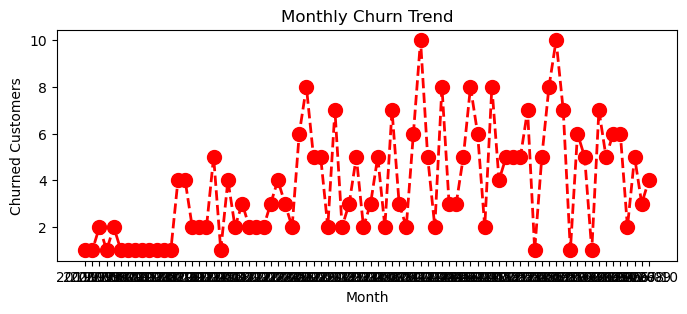

In [59]:
# 4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values,  color = 'red', marker = 'o', linestyle = 'dashed',  linewidth = 2, markersize = 10)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

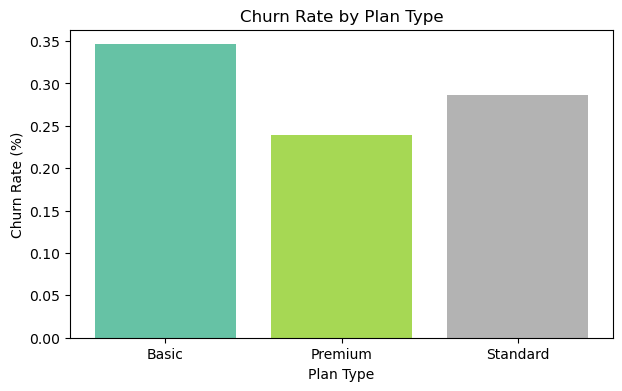

In [60]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['grey', 'pink', 'lightblue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

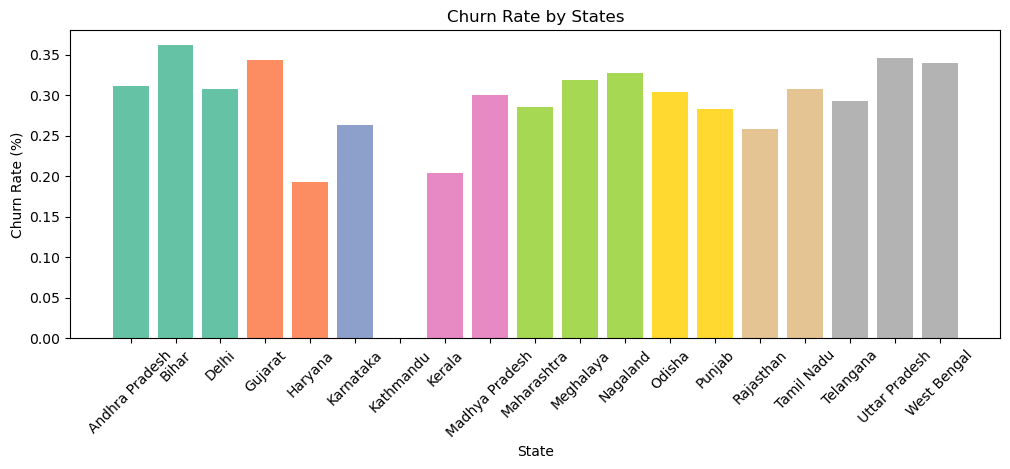

In [61]:
# 4.3 Churn by States

churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['grey', 'pink', 'lightblue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by States')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

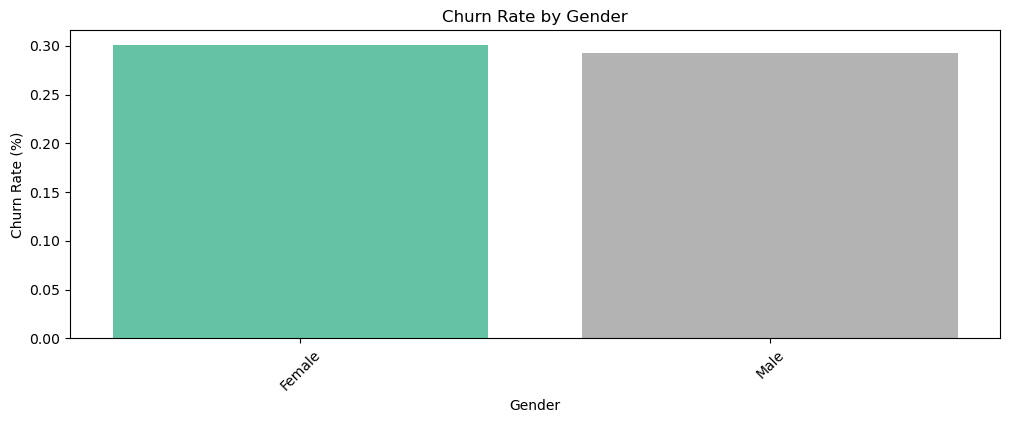

In [62]:
# 4.4 Churn by Gender

churn_plan = df_visual.groupby('gender')['churn_flag'].mean()

# colors = ['grey', 'pink', 'lightblue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

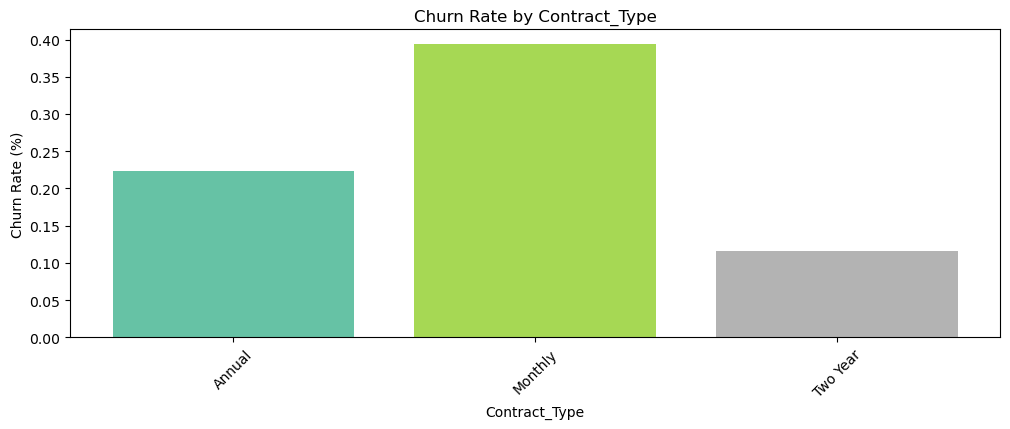

In [63]:
# 4.5 Churn by Contract_Type

churn_plan = df_visual.groupby('contract_type')['churn_flag'].mean()

# colors = ['grey', 'pink', 'lightblue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Contract_Type')
plt.xlabel('Contract_Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

## 5. Visualization using Seaborn

In [64]:
# Heatmap (Correlation Matrix)

# Encoding - convert str to numeric so that we can find correlation between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [65]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [66]:
# Remove warnings

import warnings
warnings.filterwarnings("ignore")

In [67]:
# Method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [68]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [69]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

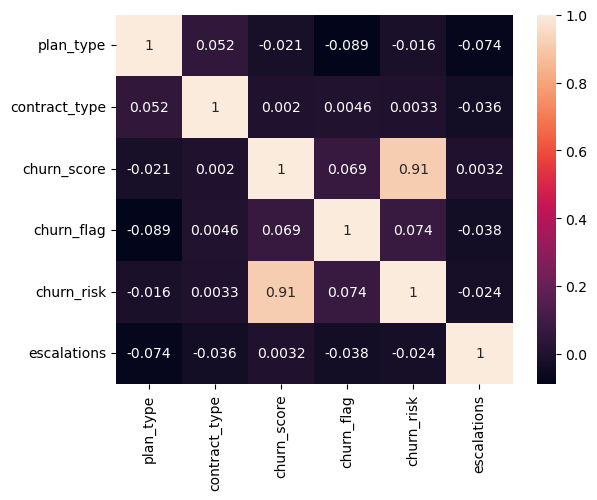

In [70]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

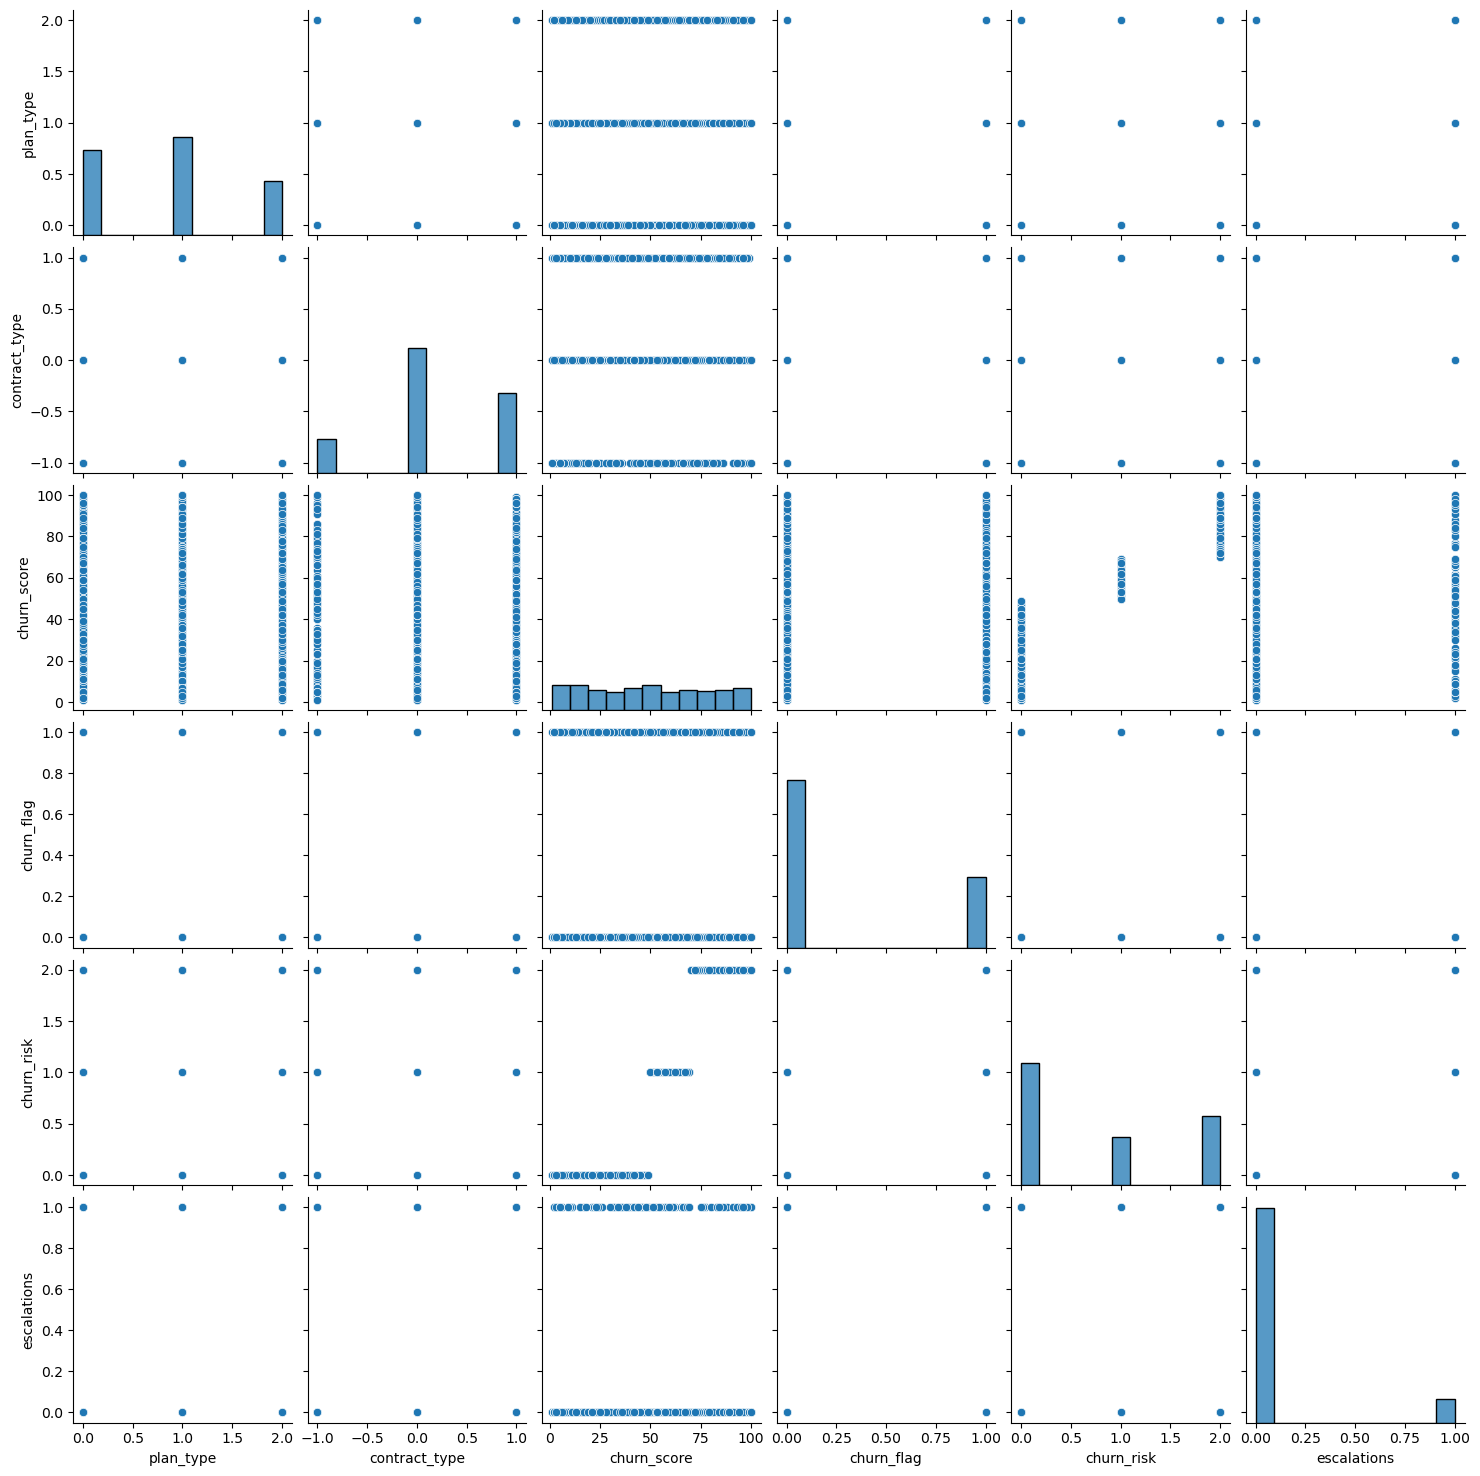

In [71]:
# pairplot - Plot pairwise relationships in a dataset
# Pairplot shows multiple charts and the relation or combination between different KPIs

sns.pairplot(df_encoded)

In [72]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

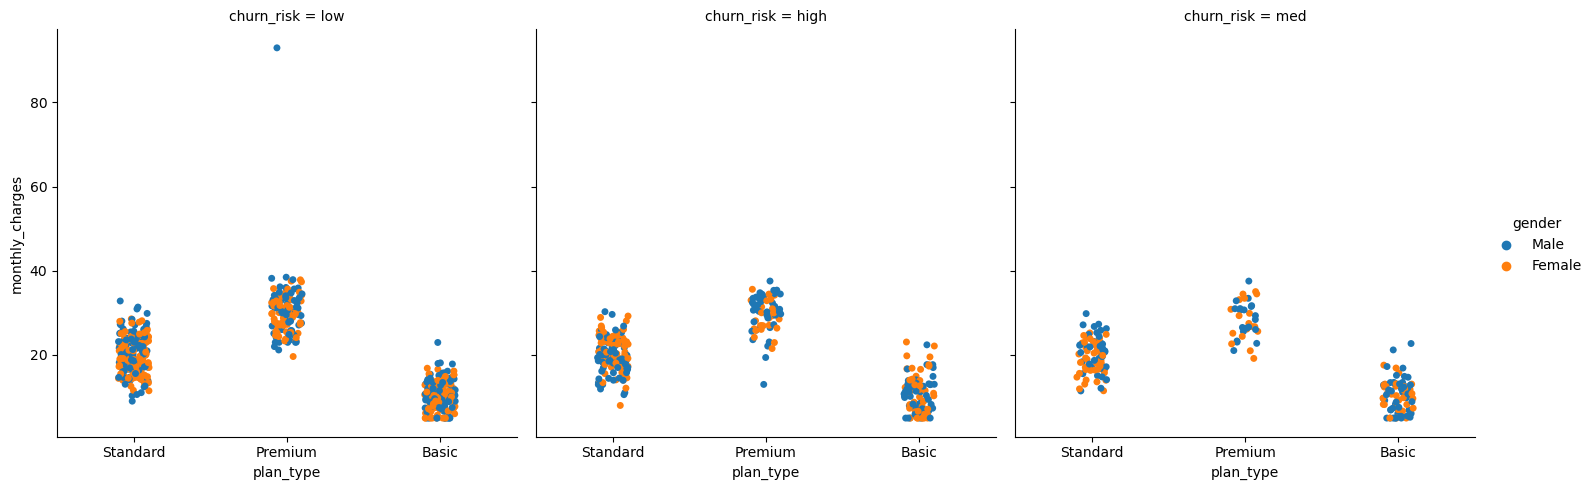

In [73]:
# catplot/Facegrid plot - multi-dimensional comparison

sns.catplot(data = df_visual,
    x = 'plan_type',
    y = 'monthly_charges',
    hue = 'gender',
    col = 'churn_risk')

## 6. Pivot Table

In [74]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index = 'plan_type',
    values = 'churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.346154
Premium,0.239316
Standard,0.286052


In [75]:
# Pivot table using multiple columns and aggregate type

pd.pivot_table(
    df_visual,
    index = 'plan_type',
    values = ['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.346154,364,3788.04
Premium,0.239316,234,6976.05
Standard,0.286052,423,8463.86
